# LSTM forecasting

Use the same trajectory task and split seeds as the RNN to examine an LSTM with explicit hidden and cell state.

The outputs below are saved from local GPU training. Documentation builds render these saved outputs without running cells.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd() if (Path.cwd() / 'examples').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import jax
import numpy as np
import pandas as pd
import neuraljaxwork as nj
from neuraljaxwork import models, training
from IPython.display import display, Image, Code
RUN = ROOT / 'runs' / 'gallery/lstm'
print(f"NeuralJAXwork {nj.__version__} · JAX {jax.__version__}")
print(jax.devices())

NeuralJAXwork 0.1.0 · JAX 0.5.3


[CudaDevice(id=0)]


## Architecture

Input `[B,12,1]`; prediction `[B,1]`; carry `(h,c)`, both `[layers,B,H]`. Forget-gate bias starts at one.

The definition below is the actual package implementation used by this run.

In [2]:
display(Code(inspect.getsource(models.SequenceRegressor), language="python"))

class SequenceRegressor(nn.Module):
    """Next-value forecasting with an RNN or LSTM and explicit returned carry."""

    def __init__(self, features=1, hidden=32, outputs=1, kind="rnn", *, rngs):
        super().__init__()
        if kind not in ("rnn", "lstm"):
            raise ValueError("kind must be rnn or lstm")
        self.kind = kind
        self.recurrent = (nn.RNN if kind == "rnn" else nn.LSTM)(features, hidden, rngs=rngs)
        self.head = nn.Linear(hidden, outputs, rngs=rngs)

    def forward(self, x, state=None, *, lengths=None):
        _, carry = self.recurrent(x, state, lengths=lengths)
        h = carry[0] if self.kind == "lstm" else carry
        return {"prediction": self.head(h[-1]), "state": carry}

## Objective and optimization

Training uses an explicit step. Data iteration, evaluation, and artifact writing remain outside compiled computation.

In [3]:
display(Code(inspect.getsource(training.regression_step), language="python"))

@jit
def regression_step(model, optimizer, batch):
    x, y = batch
    loss, grads = value_and_grad(lambda m: F.mse_loss(m(x)["prediction"], y))(model)
    optimizer.step(grads)
    return {"loss": loss, "count": y.shape[0]}

## Reproduce the run

Select one GPU before launching Python or Jupyter: `CUDA_VISIBLE_DEVICES=0`. The recipe below creates a new run directory and does not overwrite completed results. Leave `TRAIN=False` to inspect an existing local run. Checkpoints are gitignored; this notebook retains the figures and metrics for publication.

In [4]:
from examples.train_gallery import RECIPES
import subprocess
TRAIN = False
command = [sys.executable, '-m', 'examples.run', 'lstm', '--download',
           '--output', str(RUN), *RECIPES['lstm']]
print(' '.join(command))
if TRAIN:
    subprocess.run(command,cwd=ROOT,check=True)
if not (RUN / 'report.json').exists():
    raise FileNotFoundError('Run the recipe locally before refreshing notebook outputs.')
report = json.loads((RUN / 'report.json').read_text())
configuration = report['config']
display(pd.DataFrame([{'epochs':configuration['epochs'], 'batch_size':configuration['batch_size'],
                      'seed':configuration['seed'], 'training_examples':report['train_samples'],
                      'validation_examples':report['validation_samples'],
                      'test_examples':report['test_samples']}]))
print('Training device:',', '.join(report['devices']))

/home/dev/NeuralJAXwork/.venv/bin/python -m examples.run lstm --download --output /home/dev/NeuralJAXwork/runs/gallery/lstm --epochs 40 --limit 4096 --batch-size 128


,epochs,batch_size,seed,training_examples,validation_examples,test_examples
0,40,128,0,4096,128,128


Training device: cuda:0 NVIDIA GeForce RTX 5090


## Training history

The figure reports actual epoch metrics. For supervised tasks, the checkpoint with the lowest validation loss is selected before test evaluation.

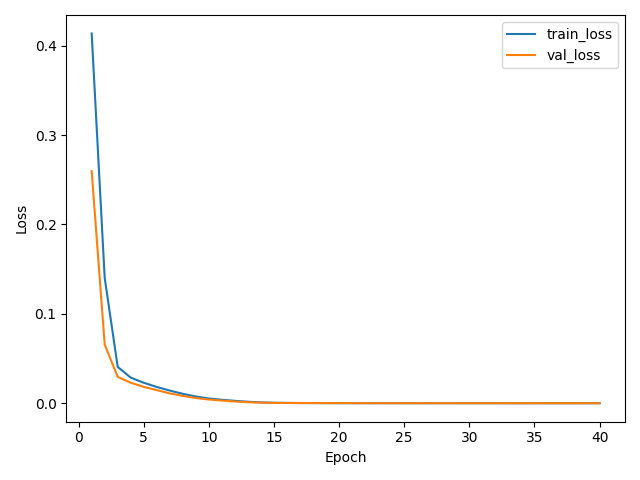

Selected epoch: 39


In [5]:
display(Image(filename=str(RUN / 'learning.png')))
if 'val_loss' in report['history'][0]:
    best_epoch = 1 + int(np.argmin([row['val_loss'] for row in report['history']]))
    print('Selected epoch:',best_epoch)

## Evaluation

Compare with the RNN at equal data and training budgets. The simpler RNN can perform better on a short smooth sequence; the results do not imply that extra recurrent gates are always useful.

In [6]:
metrics = {name:value for name,value in report.items()
           if name in ('test_loss','test_accuracy','majority_baseline_accuracy',
                       'persistence_baseline_mse','perplexity','test_auc','test_brier')}
if metrics:
    display(pd.DataFrame(list(metrics.items()),columns=['Metric','Value']))
print('Timed training loop (including validation/checkpoint work):',round(report['training_seconds'],2),'seconds')

,Metric,Value
0,test_loss,0.000043
1,persistence_baseline_mse,0.022309


Timed training loop (including validation/checkpoint work): 3.56 seconds


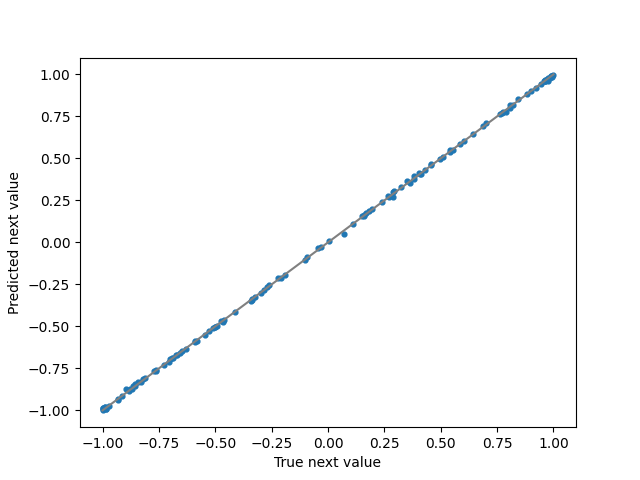

In [7]:
display(Image(filename=str(RUN / 'forecast.png')))

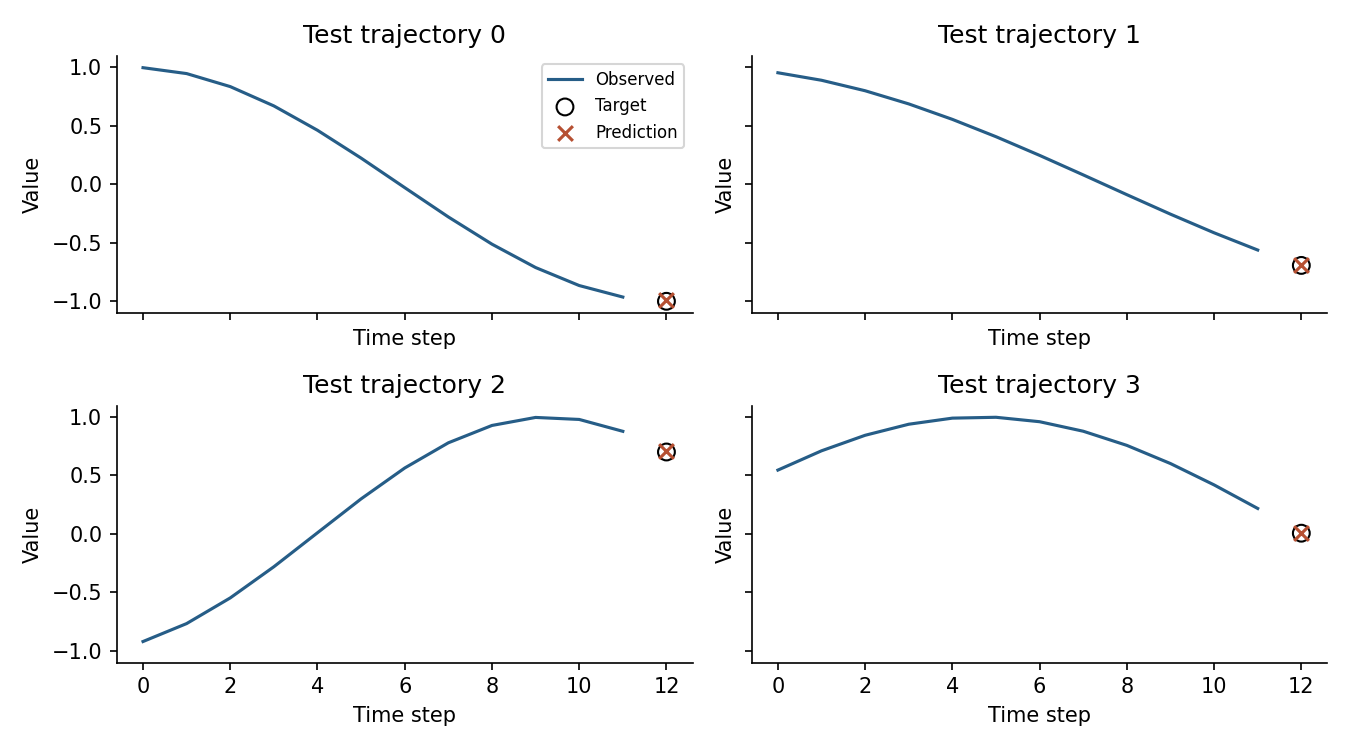

In [8]:
display(Image(filename=str(RUN / 'trajectories.png')))

## Artifacts and further work

`report.json` records the configuration and measured outcomes. `data.json` records split/preprocessing information; `best.npz` (supervised tasks) and `last.npz` contain model/training state. Figures and predictions are saved separately. Use the checkpoint tutorial to restore an existing architecture.

Change one factor at a time, retain validation-based selection, and avoid choosing configurations or samples to improve the apparent test result.